# Stock Market Prediction Using LSTM: Project Workflow:

## **Project Objective and Overview**
The objective of this project was to predict future stock prices of the <a href = "https://www.kaggle.com/datasets/henryhan117/sp-500-historical-data">**S&P 500 index**</a> using historical stock market data. A **Long Short-Term Memory (LSTM)** neural network model was developed to capture the temporal dependencies in stock prices and predict future stock movements. The primary focus of this project was on **Financial Forecasting** to help investors make data-driven decisions.

A **financial forecasting dashboard** was also built to allow users to interact with the model and visualize predicted stock prices.

---
### **Focus of the Project**:

- **Primary Application**: **Financial Forecasting**
  - Future stock prices were predicted, providing actionable insights for investors.
  
- **Core Model**: **LSTM Neural Network**
  - The LSTM model was selected for its effectiveness in time series forecasting, especially in capturing trends and temporal patterns.

---
### **Phase-Wise Project Flow: Headings**

#### **Phase 1: Data Preprocessing & Basic Data Understanding**

1. **Data Loading and Initial Exploration**  
   - Loading historical stock data and examining its structure.
   
2. **Data Cleaning and Type Modification**  
   - Converting `Date` to datetime and removing redundant columns.
   
3. **Handling Missing Values and Checking for Duplicates**  
   - Ensuring no missing values or duplicate records exist.

4. **Outlier Detection and Handling**  
   - Identifying and addressing outliers in `Adj Close` and `Volume`.

5. **Feature Scaling**  
   - Applying Min-Max Scaling to normalize relevant features.

---

#### **Phase 2: Exploratory Data Analysis (EDA)**

1. **Visualizing Stock Price Trends**  
   - Analyzing trends in stock prices using time series plots.

2. **Volume Analysis**  
   - Examining trading activity via volume distribution plots.

---

#### **Phase 3: Data Preparation for Modeling**

1. **Time Series Data Preparation**  
   - Creating lagged features using a look-back window for forecasting.

2. **Train-Test Split**  
   - Splitting data into training and testing sets while preserving time order.

---

#### **Phase 4: Model Building**

1. **Model Selection (LSTM)**  
   - Selecting the LSTM model for time series prediction.

2. **Model Training**  
   - Training the LSTM model on historical stock data.

3. **Model Evaluation**  
   - Evaluating the model’s accuracy with actual vs predicted values.

---

#### **Phase 5: Post-Modeling Analysis**

1. **Predictions and Future Forecasting**  
   - Using the LSTM model to predict future stock prices.

---

#### **Phase 6: Deployment and Presentation**

1. **Building a Dashboard for Financial Forecasting**  
   - Developing a Streamlit dashboard to visualize stock price trends.

2. **Deploying the Application**  
   - Deploying the dashboard on a cloud platform for real-time use.

---

#### **Phase 7: Testing & Monitoring**

1. **Testing on New Data**  
   - Testing the model’s performance on unseen data.

2. **Real-Time Prediction Updates**  
   - Enabling real-time stock predictions with live data updates.

---

#### **Phase 8: Future Enhancements**

1. **Improving Accuracy**  
   - Exploring additional models and external data for improved predictions.

2. **Algorithmic Trading (Optional)**  
   - Integrating predictions with trading APIs for automated trading.

---



#### Let's Start off with the project Implementation Phase wise- 

## Phase 1: Data Preprocessing & Basic Data Understanding
In this phase, we focus on preparing the data for modeling by performing the following key steps:

1. **Data Loading and Initial Exploration**:
   - Loading the historical stock data of the S&P 500 index and inspecting its structure.

2. **Data Cleaning and Type Modification**:
   - Converting the `Date` column to datetime format and removing unnecessary columns (`Open`, `High`, `Low`, `Close`) to avoid redundancy.

3. **Handling Missing Values and Duplicates**:
   - Checking for missing values and duplicates to ensure data integrity.

4. **Outlier Detection and Handling**:
   - Identifying outliers in `Adj Close` and `Volume` using boxplots and applying the Cap/Floor method to handle extreme values.

5. **Feature Scaling**:
   - Applying **Min-Max Scaling** to normalize the `Adj Close` and `Volume` columns, preparing them for machine learning models.

This ensures the dataset is clean, preprocessed, and ready for further analysis and model development in the next phase. Starting with

---

### 1.1. Data Loading and Initial Exploration:

In [1]:
# Importing necessary libraries
import numpy as np # For Cap/Floor
import pandas as pd  # For data manipulation and loading
import seaborn as sns  # For visualizations
import matplotlib.pyplot as plt  # For visualizations
from sklearn.preprocessing import MinMaxScaler  # For feature scaling

In [2]:
# Loading the dataset
file_path = '../data/SPX.csv'
data = pd.read_csv(file_path)
df = data.copy()
# Displaying the first few rows
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1927-12-30,17.660000,17.660000,17.660000,17.660000,17.660000,0
1,1928-01-03,17.760000,17.760000,17.760000,17.760000,17.760000,0
2,1928-01-04,17.719999,17.719999,17.719999,17.719999,17.719999,0
3,1928-01-05,17.549999,17.549999,17.549999,17.549999,17.549999,0
4,1928-01-06,17.660000,17.660000,17.660000,17.660000,17.660000,0


In [3]:
# Checking the structure of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23323 entries, 0 to 23322
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       23323 non-null  object 
 1   Open       23323 non-null  float64
 2   High       23323 non-null  float64
 3   Low        23323 non-null  float64
 4   Close      23323 non-null  float64
 5   Adj Close  23323 non-null  float64
 6   Volume     23323 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 1.2+ MB


We can see that the `Date` column is suppose to be in Datetime format ubt is in object-string format. Therefore for proper analysis, it is suppose to be Modified.

In [4]:
# Checking for summary statistics
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,23323.000000,23323.000000,23323.000000,23323.000000,23323.000000,2.332300e+04
mean,486.821737,489.690119,483.762812,486.918598,486.918598,7.691668e+08
std,726.187716,730.112168,721.890344,726.278798,726.278798,1.484864e+09
min,4.400000,4.400000,4.400000,4.400000,4.400000,0.000000e+00
25%,23.855001,23.855001,23.855001,23.855001,23.855001,1.280000e+06
50%,99.500000,100.309998,98.720001,99.500000,99.500000,1.734000e+07
75%,834.035004,843.744995,822.889984,834.704987,834.704987,5.378550e+08
max,3564.739990,3588.110107,3535.229980,3580.840088,3580.840088,1.145623e+10


<font size="4"> **Inference from the Statistical Summary**: </font>

1. **Stock Price Range**: Stock prices range from **4.40** to **3580.84**, with a mean of **486.91** and a high standard deviation of **726.28**, indicating significant variation in prices over time. The wide spread reflects major market fluctuations from 1927 to 2020.

2. **Volume Variation**: The trading volume shows a wide range from **0 to 1.15e+10** shares, with a mean of **769 million shares** and a high standard deviation. This suggests considerable volatility in trading activity, possibly due to market conditions or data inconsistencies (e.g., non-trading days).

3. **Outliers**: Both stock prices and volume contain **significant outliers**, especially the maximum volume and minimum stock prices. These outliers may skew the model and will need to be addressed.

4. **Potential Data Issues**: The presence of **0** values in the `Volume` column requires further investigation to determine whether they represent non-trading days or data issues.

5. **Redundancy in Price Columns**: High similarity in summary statistics for `Open`, `High`, `Low`, `Close`, and `Adj Close` suggests potential redundancy, which will be confirmed by checking the correlation matrix.

---


### 1.2. Data Cleaning and Type Modification: 
#### 1.2.1. Converting 'Date' Column to Datetime -

In [5]:
# Converting 'Date' column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Verifying the conversion
df.dtypes

Date         datetime64[ns]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object

#### 1.2.2. Investigating Redundancy in Stock Price Columns (Correlation Matrix)
To decide whether `Open`, `High`, `Low`, and `Close` are unnecessary, let's examine their correlation with Adj Close. If these columns are highly correlated, we will drop them to avoid redundancy.

We will be considering only the columns related to stock prices (`Open`, `High`, `Low`, `Close`, `Adj Close`, and `Volume`) for the correlation matrix as they are directly tied to price movements. This focus helps identify multicollinearity and ensures we analyze the most relevant features for our model.

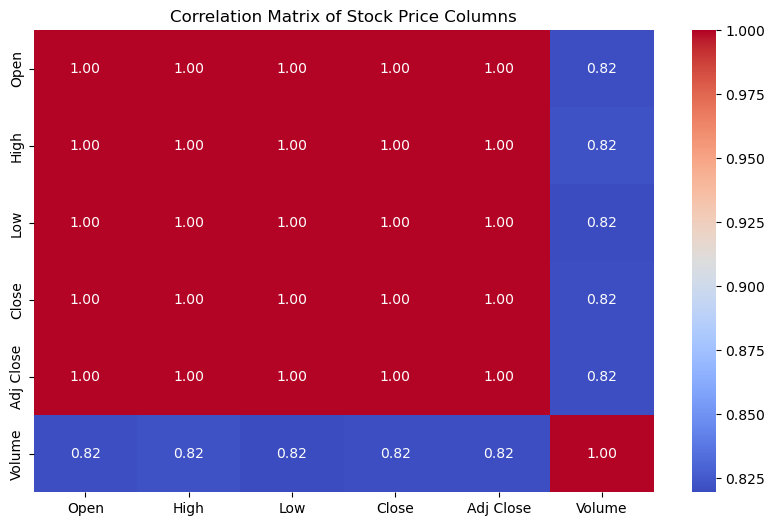

In [6]:
# Generating the correlation matrix for stock price columns
corr_matrix = df[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].corr()

# Plotting correlation matrix using heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Stock Price Columns')
plt.show()

Based on this matrix, it is evident that `Open`, `High`, `Low`, and `Close` are perfectly correlated with `Adj Close`. Therefore, keeping Adj Close and dropping the other columns would reduce redundancy and multicollinearity.

#### 1.2.2.1. Dropping Unneccessary Columns:

In [7]:
# Dropping unnecessary columns based on correlation analysis
df.drop(columns=['Open', 'High', 'Low', 'Close'], inplace=True)

# Verifying the remaining columns
df.columns

Index(['Date', 'Adj Close', 'Volume'], dtype='object')

Now that wea re only left with the most relevant features for the analysis and modelling, let's proceed with the Data Pre-processing - 

### 1.3. Handling Missing Values and Checking for Duplicates:
Next, we'll check for missing values and duplicates to ensure that our dataset is clean.

#### 1.3.1. Checking for Missing Values -



In [9]:
# Checking for missing values in the dataset
print("Missing values in each column:\n")
df.isnull().sum()

Missing values in each column:



Date         0
Adj Close    0
Volume       0
dtype: int64

As we can see, there are no Null (NaN) values in our dataset, so we will proceed forther with the exploration of our dataset.

#### 1.3.2. Checking for Duplicates - 

In [10]:
# Checking for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


As we can see, there are no duplicate rows aswell, so we will proceed further with the pre-processing stage.

### 1.4. Identifying and Handling Outliers:
#### 1.4.1. Visualizing Outliers with Boxplots

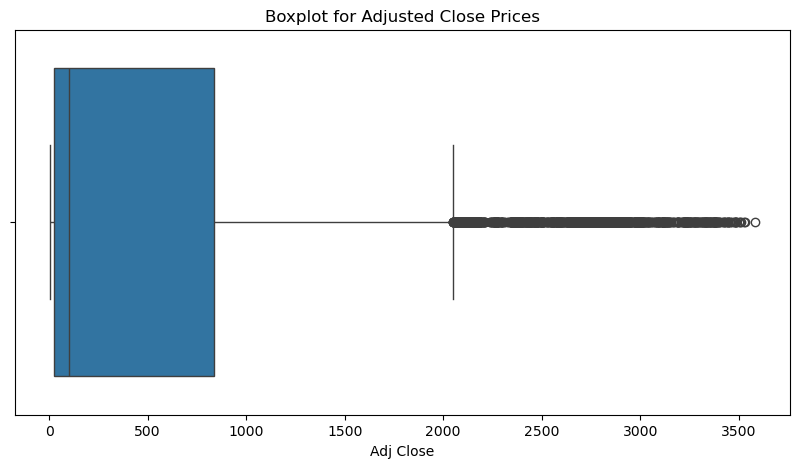

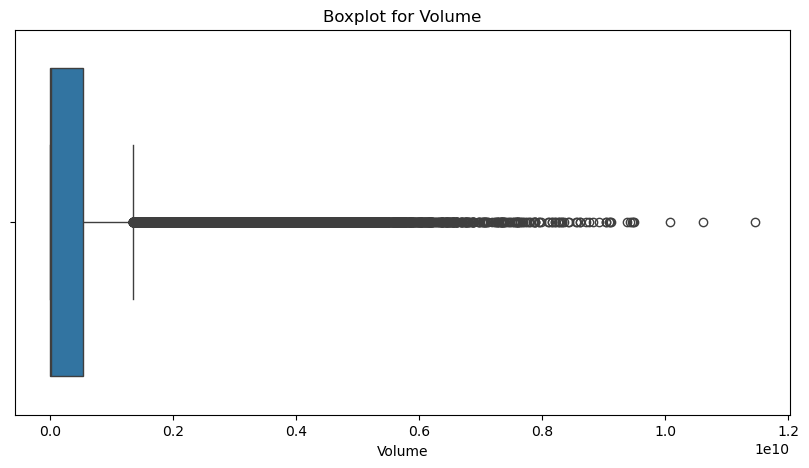

In [11]:
# Boxplot for 'Adj Close'
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['Adj Close'])
plt.title('Boxplot for Adjusted Close Prices')
plt.show()

# Boxplot for 'Volume'
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['Volume'])
plt.title('Boxplot for Volume')
plt.show()


Based on the box plots, it is evident that there are outliers in both the `Adjusted Close` prices and `Volume` columns.

#### 1.4.2. Handling Outliers using Cap/Floor Method
If there are significant outliers, we can handle them using the Cap/Floor method to limit the impact of extreme values without removing rows from the dataset.

##### <font size="3"> **Applying Cap/Floor to Handle Outliers**</font><br>
Before proceeding, let's see what Cap/Floor concept is - 
#### Cap/Floor Concept

**Cap/Floor** is a technique for handling **outliers** in a dataset by limiting extreme values without removing them.

- **Cap**: Sets an upper limit for extreme values, replacing any value above this limit with the "cap".
- **Floor**: Sets a lower limit, replacing any value below this limit with the "floor".

#### Why Use:
- To minimize the impact of outliers without losing data.
- Ensures that outliers are still present but controlled.

#### Steps:
1. **Calculate IQR**: Use the interquartile range (IQR) to determine typical value ranges.
   - Q1: 25th percentile
   - Q3: 75th percentile
   - IQR = Q3 - Q1
2. **Set bounds**: 
   - Lower bound: `Q1 - 1.5 * IQR`
   - Upper bound: `Q3 + 1.5 * IQR`
3. **Cap/Floor** values: Replace values exceeding the bounds with the upper/lower limit.

This method would retain the outliers but restricts their influence.

Now, let's continue with setting boundaries and implementing Cap/Floor using **`numpy.clip()`**:

In [16]:
# Calculating IQR for 'Adj Close' and 'Volume'
Q1 = df[['Adj Close', 'Volume']].quantile(0.25)
Q3 = df[['Adj Close', 'Volume']].quantile(0.75)
IQR = Q3 - Q1

# Defining outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [13]:
# Cap/Floor 'Adj Close'
df['Adj Close'] = np.clip(df['Adj Close'], lower_bound['Adj Close'], upper_bound['Adj Close'])

# Cap/Floor 'Volume'
df['Volume'] = np.clip(df['Volume'], lower_bound['Volume'], upper_bound['Volume'])

# Verifying that the outliers have been handled
df[['Adj Close', 'Volume']].describe()


,Adj Close,Volume
count,23323.000000,2.332300e+04
mean,454.781843,3.515465e+08
std,631.479396,5.369135e+08
min,4.400000,0.000000e+00
25%,23.855001,1.280000e+06
50%,99.500000,1.734000e+07
75%,834.704987,5.378550e+08
max,2050.979967,1.342718e+09


**Plot to Verify -**

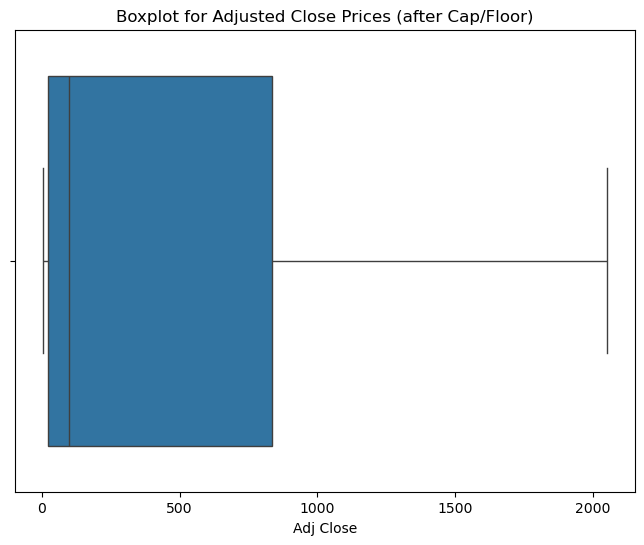

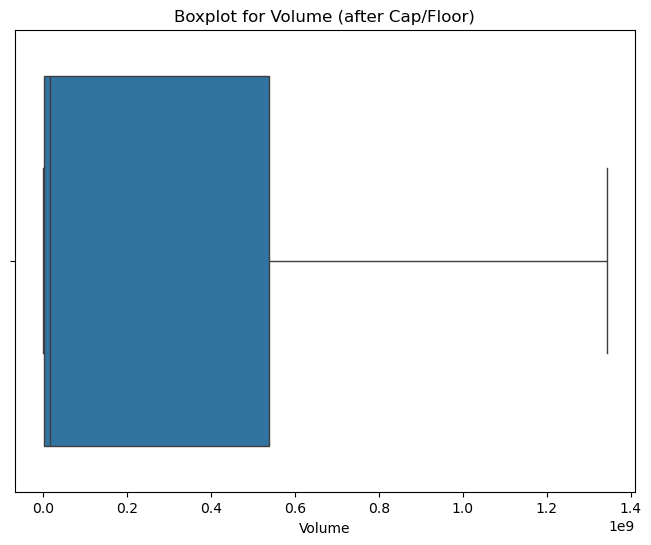

In [14]:
#Boxplot for 'Adj Close' after Cap/Floor
plt.figure(figsize=(8,6))
sns.boxplot(x=df['Adj Close'])
plt.title('Boxplot for Adjusted Close Prices (after Cap/Floor)')
plt.show()

#Boxplot for 'Volume' after Cap/Floor
plt.figure(figsize=(8,6))
sns.boxplot(x=df['Volume'])
plt.title('Boxplot for Volume (after Cap/Floor)')
plt.show()

It looks like the cap and floor method has been successfully applied, and the outliers have been handled without removing any rows. The `max` values of both `Adj Close` and `Volume` are now within the capped boundaries, indicating that extreme outliers were successfully handled.

Now that we've handled the outliers using cap/floor, we can move on to the next data preprocessing step: **Feature Scaling**.

### 1.5. Feature Scaling - 
Feature scaling ensures that all the features (columns) are on the same scale, which is particularly important for algorithms that rely on distance calculations (e.g., neural networks, k-nearest neighbors). There are a couple of common scaling methods:

1. **Standardization (Z-Score Normalization)**: Transforms the data to have a mean of 0 and a standard deviation of 1.
2. **Min-Max Scaling**: Transforms the data into a range (typically between 0 and 1).

For stock market prediction, both methods are commonly used, but **Min-Max Scaling** is often preferred, especially when using neural networks (like LSTM models).

In [15]:
# Initializing the MinMaxScaler
scaler = MinMaxScaler()

# Applying Min-Max Scaling to 'Adj Close' and 'Volume' columns
df[['Adj Close', 'Volume']] = scaler.fit_transform(df[['Adj Close', 'Volume']])

# Verifying the scaling by checking the summary statistics
df[['Adj Close', 'Volume']].describe()


,Adj Close,Volume
count,23323.000000,23323.000000
mean,0.220066,0.261817
std,0.308553,0.399871
min,0.000000,0.000000
25%,0.009506,0.000953
50%,0.046468,0.012914
75%,0.405704,0.400572
max,1.000000,1.000000


We can see that The Min-Max Scaling has been successfully applied to both the `Adj Close` and `Volume` columns. As shown in the output:

- Both columns are now scaled between 0 and 1.
- The mean, minimum, and maximum values all fall within the expected range after scaling, which is crucial for optimizing the performance of the LSTM mode

Which now brings us to the Start of PHASE 2's Implementation!

**Moving to Phase 2: Exploratory Data Analysis (EDA)**
This phase will involve visualizing the trends in `Adj Close` prices over time and analyzing the volume distribution to gain further insights before modeling.

## Phase 2: Exploratory Data Analysis (EDA)
